In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2
import time




bloco = 0
r_seed = 42

from pathlib import Path
WORKDIR = str(Path.cwd().parent) + '/'  # raiz do repositório
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/logs/"+data_hora

In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR + 'Data/processed/activity_recognition_data_watch_concat_by_comparacao_grupos.csv')

In [4]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.091625,-0.591667,8.195502,90426757696641,0.314944,-1.022277,-0.309962
1,1600,0,90426757696641,4.972757,-0.158317,6.696732,90426807196641,0.387382,-0.618541,-0.048972
2,1600,0,90426807196641,3.253720,-0.191835,6.107758,90426856696641,0.070999,-0.209480,-0.195978
3,1600,0,90426856696641,2.801216,-0.155922,5.997625,90426906196641,0.037975,0.254976,-0.156563
4,1600,0,90426906196641,3.770868,-1.051354,7.731027,90426955696641,0.073129,0.719431,-0.001035


In [5]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [6]:
#remove the null class
data=data.dropna()

# **Data Exploration**

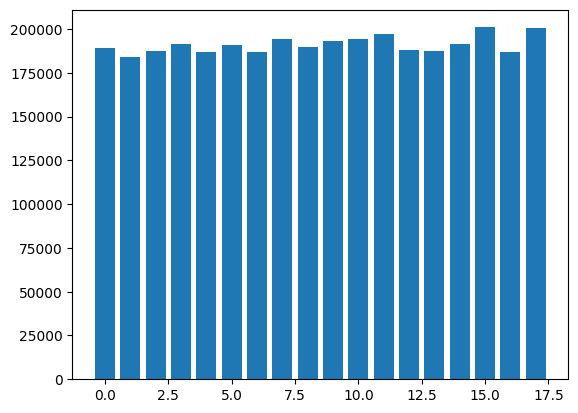

In [7]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

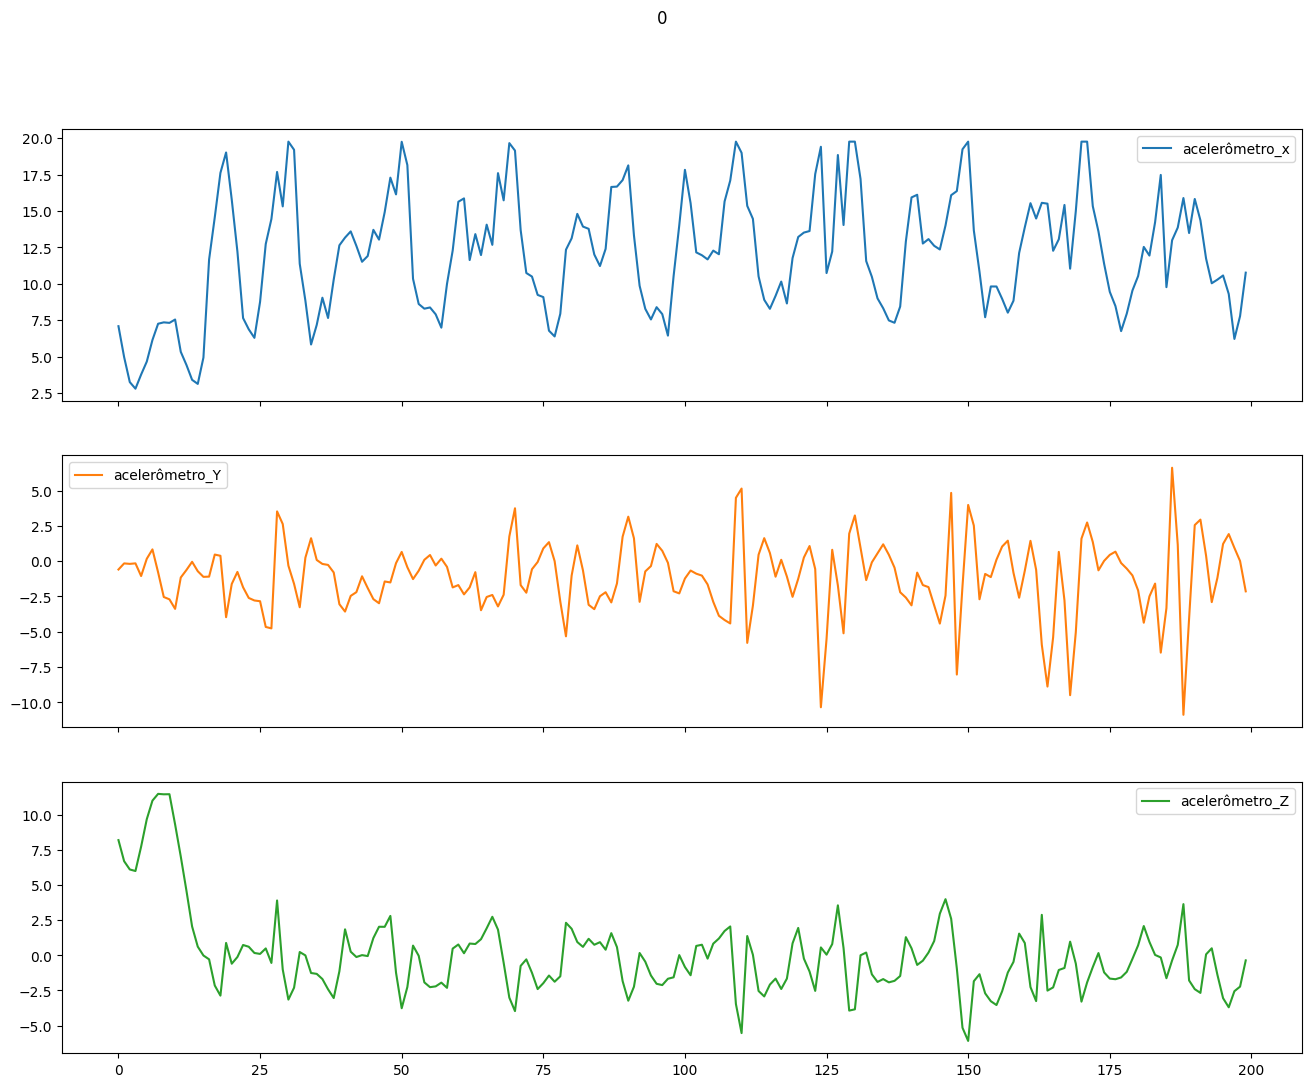

In [8]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

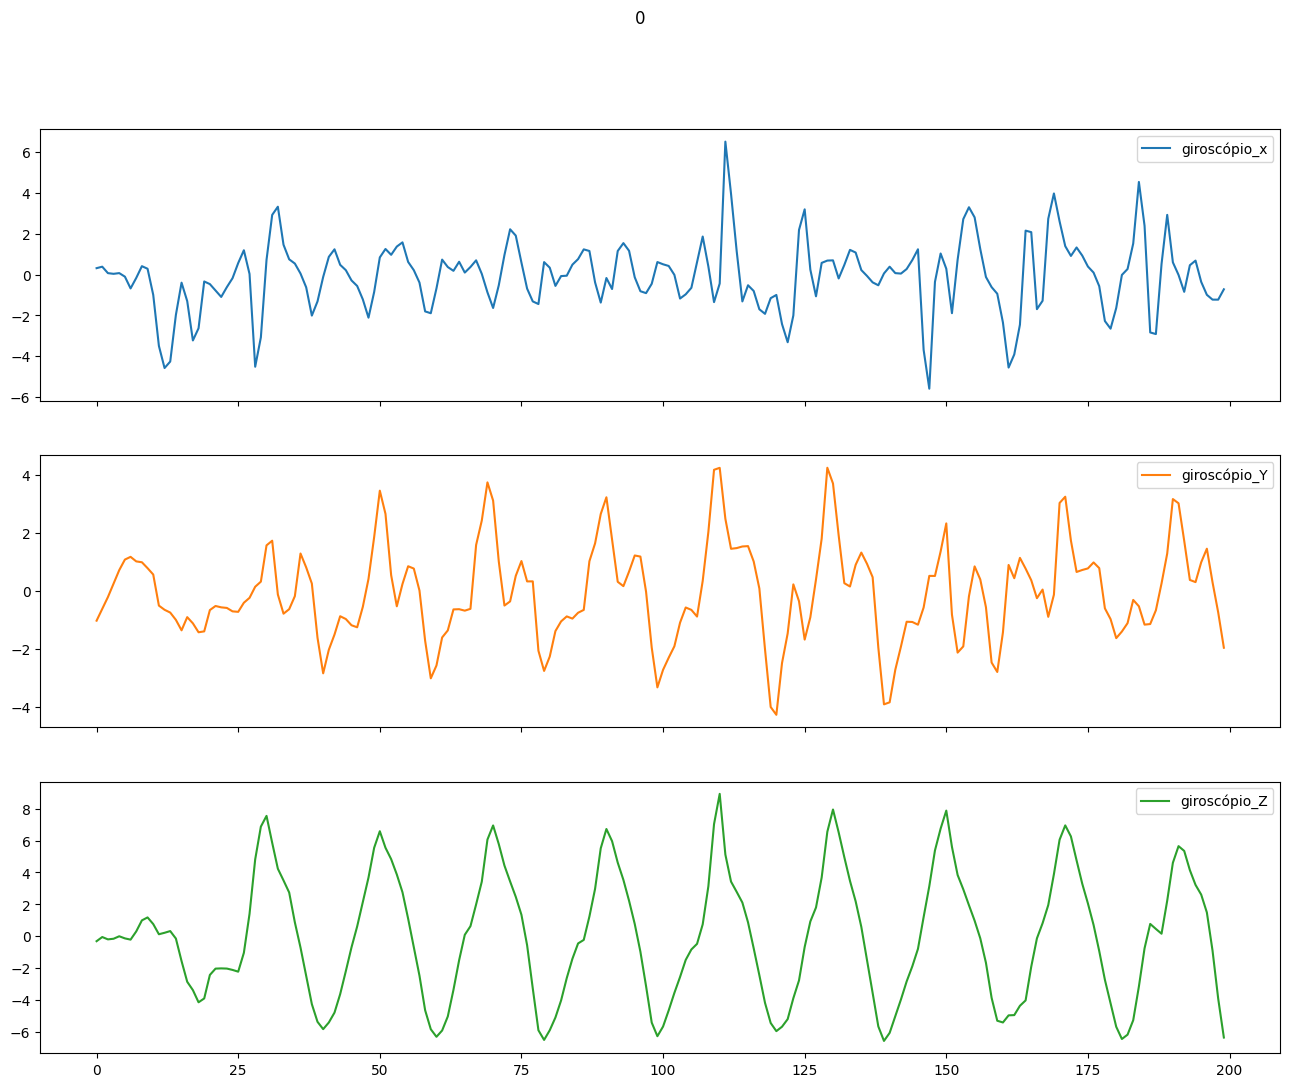

In [9]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

In [10]:
data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().sort_index()

(Index([1629, 1639, 1604, 1638, 1640, 1637, 1621, 1624, 1628, 1644, 1609, 1602,
        1608, 1645, 1626, 1620, 1617, 1625, 1650, 1607, 1647, 1600, 1612, 1649,
        1610, 1634, 1615, 1627, 1630, 1631, 1632, 1635, 1636, 1622, 1611, 1633,
        1606, 1613, 1623, 1619, 1614, 1601, 1648, 1643, 1641, 1646, 1618, 1616,
        1603, 1605, 1642],
       dtype='int64', name='pessoa_x'),
 pessoa_x
 1600     65435
 1601     64825
 1602     68553
 1603     61246
 1604     72076
 1605     60296
 1606     64854
 1607     65808
 1608     68156
 1609     69625
 1610     64879
 1611     64855
 1612     65250
 1613     64844
 1614     64831
 1615     64869
 1616     61251
 1617     66976
 1618     61264
 1619     64833
 1620     67158
 1621     71336
 1622     64855
 1623     64839
 1624     71239
 1625     66672
 1626     67272
 1627     64863
 1628     70348
 1629    129738
 1630     64860
 1631     64859
 1632     64858
 1633     64854
 1634     64871
 1635     64858
 1636     64857
 1637     7

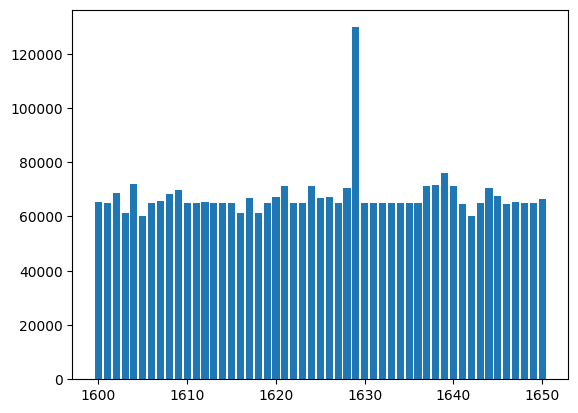

In [11]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [12]:
data.shape

(3441622, 10)

In [13]:
data = data[data["pessoa_x"]!=1629]

In [14]:
data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().sort_index()

(Index([1639, 1604, 1638, 1640, 1637, 1621, 1624, 1628, 1644, 1609, 1602, 1608,
        1645, 1626, 1620, 1617, 1625, 1650, 1607, 1647, 1600, 1612, 1649, 1610,
        1634, 1615, 1627, 1630, 1631, 1632, 1635, 1636, 1622, 1611, 1606, 1633,
        1613, 1623, 1619, 1614, 1601, 1648, 1643, 1641, 1646, 1618, 1616, 1603,
        1605, 1642],
       dtype='int64', name='pessoa_x'),
 pessoa_x
 1600    65435
 1601    64825
 1602    68553
 1603    61246
 1604    72076
 1605    60296
 1606    64854
 1607    65808
 1608    68156
 1609    69625
 1610    64879
 1611    64855
 1612    65250
 1613    64844
 1614    64831
 1615    64869
 1616    61251
 1617    66976
 1618    61264
 1619    64833
 1620    67158
 1621    71336
 1622    64855
 1623    64839
 1624    71239
 1625    66672
 1626    67272
 1627    64863
 1628    70348
 1630    64860
 1631    64859
 1632    64858
 1633    64854
 1634    64871
 1635    64858
 1636    64857
 1637    71414
 1638    71426
 1639    75868
 1640    71415
 1641    

In [15]:
data.shape

(3311884, 10)

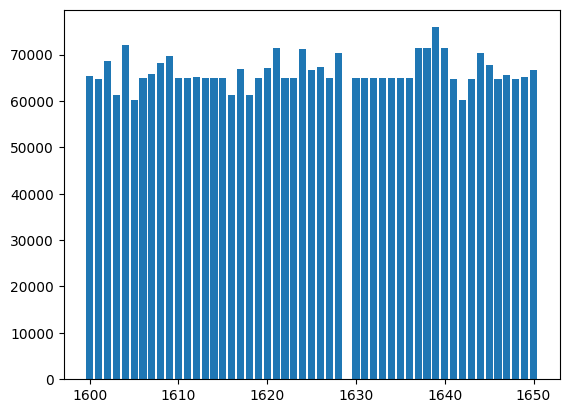

In [16]:
plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [17]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3])]

In [18]:
data['root_sum_square_acel_xyz'] = np.sqrt(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']].pow(2).sum(axis=1))

In [19]:
data['root_sum_square_acel_xy'] = np.sqrt(data[['acelerômetro_x', 'acelerômetro_Y']].pow(2).sum(axis=1))

In [20]:
data['root_sum_square_acel_xz'] = np.sqrt(data[['acelerômetro_x', 'acelerômetro_Z']].pow(2).sum(axis=1))

In [21]:
data['root_sum_square_acel_yz'] = np.sqrt(data[['acelerômetro_Y', 'acelerômetro_Z']].pow(2).sum(axis=1))

In [22]:
data['mean_acel'] = np.mean(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']],axis=1)

In [23]:
data['standard_acel'] = np.std(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']],axis=1)

In [24]:
data['min_acel'] = np.min(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']],axis=1)

In [25]:
data['max_acel'] = np.max(data[['acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z']],axis=1)

In [26]:
data['root_sum_square_giro'] = np.sqrt(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']].pow(2).sum(axis=1))

In [27]:
data['root_sum_square_giro_xy'] = np.sqrt(data[['giroscópio_x', 'giroscópio_Y']].pow(2).sum(axis=1))

In [28]:
data['root_sum_square_giro_xz'] = np.sqrt(data[['giroscópio_x', 'giroscópio_Z']].pow(2).sum(axis=1))

In [29]:
data['root_sum_square_giro_yz'] = np.sqrt(data[['giroscópio_Y', 'giroscópio_Z']].pow(2).sum(axis=1))

In [30]:
data['mean_giro'] = np.mean(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']],axis=1)

In [31]:
data['standard_giro'] = np.std(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']],axis=1)

In [32]:
data['min_giro'] = np.min(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']],axis=1)

In [33]:
data['max_giro'] = np.max(data[['giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']],axis=1)

In [34]:
data.shape

(723387, 26)

In [35]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z,...,min_acel,max_acel,root_sum_square_giro,root_sum_square_giro_xy,root_sum_square_giro_xz,root_sum_square_giro_yz,mean_giro,standard_giro,min_giro,max_giro
0,1600,0,90426708196641,7.091625,-0.591667,8.195502,90426757696641,0.314944,-1.022277,-0.309962,...,-0.591667,8.195502,1.113694,1.069691,0.441889,1.068235,-0.339098,0.546307,-1.022277,0.314944
1,1600,0,90426757696641,4.972757,-0.158317,6.696732,90426807196641,0.387382,-0.618541,-0.048972,...,-0.158317,6.696732,0.731475,0.729834,0.390465,0.620477,-0.093377,0.411865,-0.618541,0.387382
2,1600,0,90426807196641,3.253720,-0.191835,6.107758,90426856696641,0.070999,-0.209480,-0.195978,...,-0.191835,6.107758,0.295517,0.221184,0.208443,0.286861,-0.111486,0.129154,-0.209480,0.070999
3,1600,0,90426856696641,2.801216,-0.155922,5.997625,90426906196641,0.037975,0.254976,-0.156563,...,-0.155922,5.997625,0.301607,0.257788,0.161103,0.299207,0.045462,0.168094,-0.156563,0.254976
4,1600,0,90426906196641,3.770868,-1.051354,7.731027,90426955696641,0.073129,0.719431,-0.001035,...,-1.051354,7.731027,0.723139,0.723138,0.073136,0.719432,0.263842,0.323570,-0.001035,0.719431


In [36]:
data.columns

Index(['pessoa_x', 'atividade', 'tempo_acelerômetro', 'acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'tempo_gyro', 'giroscópio_x',
       'giroscópio_Y', 'giroscópio_Z', 'root_sum_square_acel_xyz',
       'root_sum_square_acel_xy', 'root_sum_square_acel_xz',
       'root_sum_square_acel_yz', 'mean_acel', 'standard_acel', 'min_acel',
       'max_acel', 'root_sum_square_giro', 'root_sum_square_giro_xy',
       'root_sum_square_giro_xz', 'root_sum_square_giro_yz', 'mean_giro',
       'standard_giro', 'min_giro', 'max_giro'],
      dtype='object')

In [37]:
data = data.reset_index()

In [38]:
data.head()

,index,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,...,min_acel,max_acel,root_sum_square_giro,root_sum_square_giro_xy,root_sum_square_giro_xz,root_sum_square_giro_yz,mean_giro,standard_giro,min_giro,max_giro
0,0,1600,0,90426708196641,7.091625,-0.591667,8.195502,90426757696641,0.314944,-1.022277,...,-0.591667,8.195502,1.113694,1.069691,0.441889,1.068235,-0.339098,0.546307,-1.022277,0.314944
1,1,1600,0,90426757696641,4.972757,-0.158317,6.696732,90426807196641,0.387382,-0.618541,...,-0.158317,6.696732,0.731475,0.729834,0.390465,0.620477,-0.093377,0.411865,-0.618541,0.387382
2,2,1600,0,90426807196641,3.253720,-0.191835,6.107758,90426856696641,0.070999,-0.209480,...,-0.191835,6.107758,0.295517,0.221184,0.208443,0.286861,-0.111486,0.129154,-0.209480,0.070999
3,3,1600,0,90426856696641,2.801216,-0.155922,5.997625,90426906196641,0.037975,0.254976,...,-0.155922,5.997625,0.301607,0.257788,0.161103,0.299207,0.045462,0.168094,-0.156563,0.254976
4,4,1600,0,90426906196641,3.770868,-1.051354,7.731027,90426955696641,0.073129,0.719431,...,-1.051354,7.731027,0.723139,0.723138,0.073136,0.719432,0.263842,0.323570,-0.001035,0.719431


In [39]:
data.shape

(723387, 27)

# **Models**

In [40]:
def split_indices_for_kfold(validation_sets):
    indices_array = []  
    for set in validation_sets:
        indice = data[(data['pessoa_x'].isin(set))].index.to_numpy()
        """ start_validation_index = data[(data['pessoa_x'].isin(set))].head(1).index[0]
        end_validation_index = data[(data['pessoa_x'].isin(set))].tail(1).index[0]"""
        indices_array.append(indice)        
    return indices_array       


In [41]:
""" def create_participants_sets_for_validation():
    import random
    numbers = [num for num in range(1600, 1651) if num != 1629]  # Create a list of numbers from 1600 to 1650
    validation_participants_sets = np.empty((5, 10), dtype=int)  # 5 rows, 3 columns

    position = 0
    while numbers:  # Loop until the list is empty
        random_values = random.sample(numbers, 10)  # Get 10 random values without replacement
        #print(random_values)  # Print the random values
        numbers = [num for num in numbers if num not in random_values]  # Remove the selected values from the list
        validation_participants_sets[position]=random_values
        position = position+1
    return validation_participants_sets """

' def create_participants_sets_for_validation():\n    import random\n    numbers = [num for num in range(1600, 1651) if num != 1629]  # Create a list of numbers from 1600 to 1650\n    validation_participants_sets = np.empty((5, 10), dtype=int)  # 5 rows, 3 columns\n\n    position = 0\n    while numbers:  # Loop until the list is empty\n        random_values = random.sample(numbers, 10)  # Get 10 random values without replacement\n        #print(random_values)  # Print the random values\n        numbers = [num for num in numbers if num not in random_values]  # Remove the selected values from the list\n        validation_participants_sets[position]=random_values\n        position = position+1\n    return validation_participants_sets '

In [42]:
#random_participants_sets = create_participants_sets_for_validation()

In [43]:
#print(random_participants_sets)

In [44]:
validation_set1=[1600,1605,1610,1615,1620,1625,1631,1636,1641,1646]
validation_set2=[1601,1606,1611,1616,1621,1626,1632,1637,1642,1647]
validation_set3=[1602,1607,1612,1617,1622,1627,1633,1638,1643,1648]
validation_set4=[1603,1608,1613,1618,1623,1628,1634,1639,1644,1649]
validation_set5=[1604,1609,1614,1619,1624,1630,1635,1640,1645,1650]
combined_validation_sets = [validation_set1,validation_set2, validation_set3, validation_set4, validation_set5]
split_indices = split_indices_for_kfold(combined_validation_sets)

In [45]:
print(split_indices)

[array([     0,      1,      2, ..., 663349, 663350, 663351], dtype=int64), array([ 14415,  14416,  14417, ..., 678419, 678420, 678421], dtype=int64), array([ 32420,  32421,  32422, ..., 692816, 692817, 692818], dtype=int64), array([ 46832,  46833,  46834, ..., 707222, 707223, 707224], dtype=int64), array([ 57638,  57639,  57640, ..., 723384, 723385, 723386], dtype=int64)]


In [46]:
for elem in split_indices:    
        print(f"total percentual={(len(elem))/data.shape[0]}")    

total percentual=0.19424180970904922
total percentual=0.19967735112740484
total percentual=0.20394201167563145
total percentual=0.1989225684177349
total percentual=0.2032162590701796


In [47]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [48]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x',
       'giroscópio_Y', 'giroscópio_Z', 'root_sum_square_acel_xyz',
       'root_sum_square_acel_xy', 'root_sum_square_acel_xz',
       'root_sum_square_acel_yz', 'mean_acel', 'standard_acel', 'min_acel',
       'max_acel', 'root_sum_square_giro', 'root_sum_square_giro_xy',
       'root_sum_square_giro_xz', 'root_sum_square_giro_yz', 'mean_giro',
       'standard_giro', 'min_giro', 'max_giro']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [49]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [50]:
def cria_LSTM():
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(units=128, kernel_regularizer=l2(0.0005377164071193433),
             recurrent_regularizer=l2(0.0005377164071193433), input_shape=(200,22), return_sequences=False))  
  model.add(tf.keras.layers.Dense(units = 256, activation='relu'))  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001715074355925934), metrics=['accuracy'])
  return model


In [51]:
def create_validation_and_train_data(index):
    global bloco
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    print("indices que serão processados")
    print("Proximo bloco:")
    print(bloco)
        
    X_validation_data = data.loc[index]
    print(f"imprimindo shape dos dados de validação -- {X_validation_data.shape}")
    X_train_data = data.drop(X_validation_data.index)
    print("&&&&&&&&& testando se o grupo de participantes de TESTE está correto")
    print(set(X_validation_data["pessoa_x"]))
    print(f"percentual de TESTE: {X_validation_data.shape[0]/data.shape[0]}")

    print("==========> testando se o grupo de participantes de TREINO está correto")
    print(set(X_train_data["pessoa_x"]))
    print(f"percentual de TREINO: {X_train_data.shape[0]/data.shape[0]}")

    X_validation_data = X_validation_data.reset_index(drop=True)
    X_validation_data = X_validation_data.drop('index',axis=1)
    X_validation_data.info()
    X_validation_data['atividade'].value_counts()
    X_validation_data = X_validation_data[['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x',
       'giroscópio_Y', 'giroscópio_Z', 'root_sum_square_acel_xyz',
       'root_sum_square_acel_xy', 'root_sum_square_acel_xz',
       'root_sum_square_acel_yz', 'mean_acel', 'standard_acel', 'min_acel',
       'max_acel', 'root_sum_square_giro', 'root_sum_square_giro_xy',
       'root_sum_square_giro_xz', 'root_sum_square_giro_yz', 'mean_giro',
       'standard_giro', 'min_giro', 'max_giro','atividade']]
    print(X_validation_data.shape)

    X_train_data = X_train_data.reset_index(drop=True)
    X_train_data = X_train_data.drop('index',axis=1)
    X_train_data['atividade'].value_counts()
    X_train_data = X_train_data[['acelerômetro_x',
       'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x',
       'giroscópio_Y', 'giroscópio_Z', 'root_sum_square_acel_xyz',
       'root_sum_square_acel_xy', 'root_sum_square_acel_xz',
       'root_sum_square_acel_yz', 'mean_acel', 'standard_acel', 'min_acel',
       'max_acel', 'root_sum_square_giro', 'root_sum_square_giro_xy',
       'root_sum_square_giro_xz', 'root_sum_square_giro_yz', 'mean_giro',
       'standard_giro', 'min_giro', 'max_giro','atividade']]
    print(X_train_data.shape)

    segments_val,targets_val = apply_segmentation_with_sliding_window(X_validation_data)
    print(targets_val.shape)
    print(segments_val.shape)

    segments_val,targets_val = delete_segments_not_fully_filled(segments_val,targets_val)
    print(targets_val.shape)
    print(segments_val.shape)
    print("fez a segmentação da validação no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")
    targets_val = targets_val.reshape(targets_val.shape[0],200)
    print(targets_val.shape)
    print(targets_val)
    labels_val = targets_val[:,0]
    print(labels_val)
    print(labels_val.shape)
    labels_val_categorical = to_categorical(labels_val,num_classes=4)
    print(labels_val_categorical)
    print(labels_val_categorical.shape)
    segments_train,targets_train = apply_segmentation_with_sliding_window(X_train_data)
    print(segments_train.shape)
    print(targets_train.shape)

    segments_train, targets_train = delete_segments_not_fully_filled(segments_train,targets_train)
    print(segments_train.shape)
    print(targets_train.shape)
    print("fez a segmentação do treino no horário")
    current_time = time.time() * 1000
    print(f"Current time in milliseconds: {current_time:.2f}")

    targets_train = targets_train.reshape(targets_train.shape[0],200)
    print(targets_train.shape)
    labels_train = targets_train[:,0]
    labels_train_categorical = to_categorical(labels_train,num_classes=4)
    print(labels_train_categorical)

    X_train = segments_train
    y_train = labels_train_categorical
    X_validation = segments_val
    y_validation = labels_val_categorical

    print(X_train.shape)
    print(y_train.shape)
    print(X_validation.shape)
    print(y_validation.shape)

    #X_train,y_train = shuffle_data(X_train,y_train)
    #X_validation,y_validation = shuffle_data(X_validation,y_validation)

    #print(X_train.shape)
    #print(y_train.shape)
    #print(X_validation.shape)
    #print(y_validation.shape)
    bloco = bloco+1
    print(f" %%%%%%%%%%%%%%%%%%%%%%%%%%%% retornou os dados para treinamento  %%%%%%%%%%%%%%%%%%%%")
    return (X_train,y_train,X_validation,y_validation)

In [52]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

my_callbacks = [early_stopping]  

In [53]:
#for start_index,end_index in split_indices:    
        #print(f"************ Usando indices {start_index} e {end_index} como teste ******************* ")     

************ Usando indices dados dos participantes [1600, 1605, 1610, 1615, 1620, 1625, 1631, 1636, 1641, 1646] como teste ******************* 
Current time in milliseconds: 1709747565783.85
indices que serão processados
Proximo bloco:
0
imprimindo shape dos dados de validação -- (140512, 27)
&&&&&&&&& testando se o grupo de participantes de TESTE está correto
{1600, 1636, 1605, 1641, 1610, 1646, 1615, 1620, 1625, 1631}
percentual de TESTE: 0.19424180970904922
==========> testando se o grupo de participantes de TREINO está correto
{1601, 1602, 1603, 1604, 1606, 1607, 1608, 1609, 1611, 1612, 1613, 1614, 1616, 1617, 1618, 1619, 1621, 1622, 1623, 1624, 1626, 1627, 1628, 1630, 1632, 1633, 1634, 1635, 1637, 1638, 1639, 1640, 1642, 1643, 1644, 1645, 1647, 1648, 1649, 1650}
percentual de TREINO: 0.8057581902909507
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140512 entries, 0 to 140511
Data columns (total 26 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------  

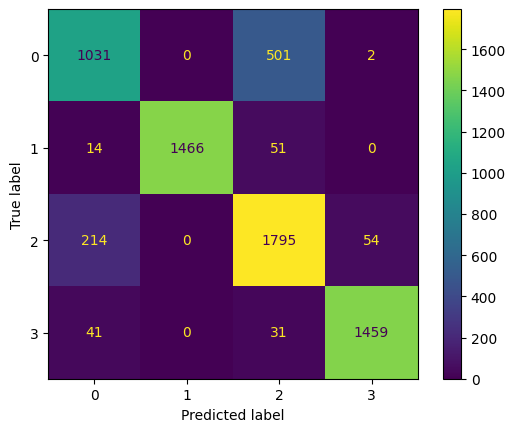

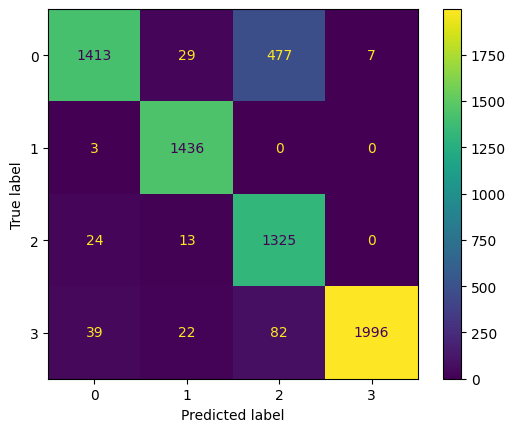

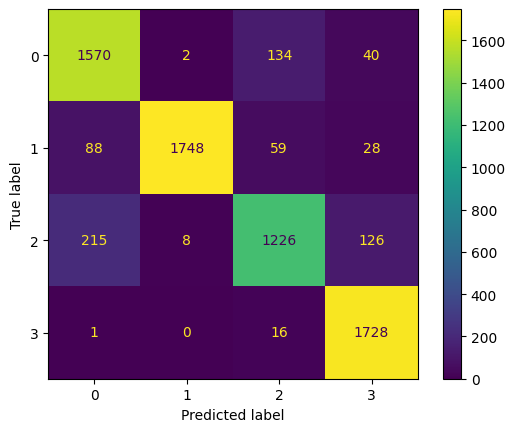

In [54]:
global combined_validation_sets
i=0 
accuracies = []
for index in split_indices:
        print(f"************ Usando indices dados dos participantes {combined_validation_sets[i]} como teste ******************* ")    
        X_train,y_train,X_validation,y_validation = create_validation_and_train_data(index)
        print (X_train)
        model  = cria_LSTM()
        model.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_validation, y_validation),use_multiprocessing=True,callbacks=[my_callbacks])  # Adjust epochs and batch size
        _, accuracy = model.evaluate(X_validation, y_validation)
        print(f"===============>Appending accuracy of {accuracy} ") 
        accuracies.append(accuracy)

        loss, accuracy = model.evaluate(X_validation, y_validation)
        predictions = model.predict(X_validation)
        print(y_validation)
        print(y_validation.shape)
        y_validation_inverse = np.argmax(y_validation, axis=1)
        print(y_validation_inverse)
        print(len(y_validation_inverse))
        print(predictions)
        classes_x=np.argmax(predictions,axis=1)
        print(classes_x)
        print(len(classes_x))
        print(classes_x.shape)
        from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
        cm = confusion_matrix(y_validation_inverse, classes_x)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot()
        print(classification_report(y_validation_inverse, classes_x))
        i = i+1
print(f"Average accuracy: {np.mean(accuracies)}")

In [ ]:
print(f"Average accuracy: {np.mean(accuracies)}")

In [ ]:
print(accuracies)